# What makes the inference slow

In [49]:
import time
import torch

from tqdm import trange
from transformers import AutoModelForCausalLM, AutoTokenizer

## Autoregressive Generation

**How a decoder-only transformer generates text**

- **Tokenize**
    - split the prompt into token IDs
    - a causal mask ensures each position can use only itself and earlier positions

**Prefill vs decode**

- **Prefill (first model call)**
    - feed the entire prompt of $P$ tokens together
    - the model processes its positions in parallel
    - produces the scores for the **first new token**
- **Decode (later model calls)**:
    - choose one token from the latest scores
    - feed that token to the model to predict the next one

**Why it is slow**

- **Sequential decoding**
    - Each new token depends on previous tokens - response needs repeated model passes
- **Prompt length**
    - A longer prefill delays the first output token

The loops below show these steps directly.

### Theoretical cost: full prefix vs KV cache

- $P$: prompt length
- $N$: number of generated tokens
- $d$: hidden width
- $L$: number of transformer layers
- $i$: generation step
- $s=P+i-1 \leq P+N$: available context

| Phase | Full prefix (no cache) | Reuse KV cache |
| --- | --- | --- |
| **Prefill: predict token 1** | $O\big(L(Pd^2+P^2d)\big)$ | Same compute, plus storing $O(LPd)$ key/value elements |
| **Later step: predict token $i$** | $O\big(L(sd^2+s^2d)\big)$ | $O\big(L(d^2+sd)\big)$ |

- **Breakdown**
    - **Prefill**
        - Layer norm: $O(Pd)$
        - Q, K, V projections: $O(Pd^2)$
        - Attention scores: $O(P^2d)$
        - Softmax and weighted values: $O(P^2d)$
        - Attention output projection: $O(P^2d)$
        - Feed-forward network: $O(Pd^2)$ (hidden layer width $\sim d$)
        - Residuals: $O(Pd)$
        - One Transformer Layer: $O(Pd^2+P^2d)$
        - LM head: $O(d^2)$ (hidden layer width $\sim d$)
    - **Decode, no cache**
        - same as prefill with $P \rightarrow s$
    - **Decode, KV-cache**
        - Q, K, V projections: $O(d^2)$ - need to project only last token
        - Attention: $O(sd)$ - need to caclulate attention of last token with the rest of the sequence (KV are reused here)
        - Feed-forward network: $O(d^2)$ need to process only last token
        - One Transformer Layer: $O(d^2+sd)$
        - LM head: $O(d^2)$ (hidden layer width $\sim d$)

- **Total for $N$ output tokens, no cache**
    - Sum the full-prefix cost over $s=P,\ldots,P+N-1$:
    $$
    O\big(L\big[d^2(NP+N^2)+d(NP^2+PN^2+N^3)\big]\big)
    $$
    - $O(N^3)$
- **Total for $N$ output tokens, with cache**
    - One prefill plus $N-1$ one-token passes:
    $$
    O\big(L\big[d^2(P+N)+d(P^2+PN+N^2)\big]\big)
    $$
    - KV-cache storage grows as $O(L(P+N)d)$
    - $O(N^2)$

In [50]:
model_id = "openai-community/gpt2-medium"
tokenizer = AutoTokenizer.from_pretrained(model_id)
model = AutoModelForCausalLM.from_pretrained(model_id).eval()

Loading weights: 100%|██████████| 292/292 [00:00<00:00, 11214.82it/s]


In [51]:
prompt = "Quantum entanglement is"
n_tokens = 1000

#### Brute force baseline
Recompute the prompt and every generated token on each pass.

In [52]:
encoded = tokenizer(prompt, return_tensors="pt")
generated_ids = encoded["input_ids"]
model_input_ids = generated_ids  # prefill: send the whole prompt once
attention_mask = encoded["attention_mask"]
model_input_ids, attention_mask

(tensor([[24915,   388,   920,   648,  1732,   318]]),
 tensor([[1, 1, 1, 1, 1, 1]]))

In [26]:
brute_steps = []
with torch.inference_mode():
    for step in trange(n_tokens):
        brute_step = time.time()
        outputs = model(
            input_ids=model_input_ids,
            attention_mask=attention_mask,
            use_cache=False
        )
        brute_steps.append(time.time() - brute_step)
        next_token = outputs.logits[:, -1, :].argmax(dim=-1, keepdim=True)
        generated_ids = torch.cat([generated_ids, next_token], dim=-1)
        if next_token.item() == tokenizer.eos_token_id:
            break
        model_input_ids = torch.cat([model_input_ids, next_token], dim=-1)
        attention_mask = torch.cat([attention_mask, attention_mask.new_ones((1, 1))], dim=-1)

100%|██████████| 1000/1000 [05:58<00:00,  2.79it/s]


#### Actual autoregressive generation (KV cache)
**Reuse `past_key_values`:**
- reuse attention key and value tensors for earlier tokens
- at every transformer layer

In [27]:
encoded = tokenizer(prompt, return_tensors="pt")
generated_ids = encoded["input_ids"]
model_input_ids = generated_ids  # prefill: send the whole prompt once
attention_mask = encoded["attention_mask"]
past_key_values = None

In [28]:
cache_steps = []
with torch.inference_mode():
    for step in trange(n_tokens):
        cache_step = time.time()
        outputs = model(
            input_ids=model_input_ids,
            attention_mask=attention_mask,
            use_cache=True,
            past_key_values=past_key_values
        )
        cache_steps.append(time.time() - cache_step)
        next_token = outputs.logits[:, -1, :].argmax(dim=-1, keepdim=True)
        generated_ids = torch.cat([generated_ids, next_token], dim=-1)
        past_key_values = outputs.past_key_values
        if next_token.item() == tokenizer.eos_token_id:
            break
        model_input_ids = next_token
        attention_mask = torch.cat([attention_mask, attention_mask.new_ones((1, 1))], dim=-1)

100%|██████████| 1000/1000 [00:27<00:00, 36.94it/s]


#### Compare forward-pass time

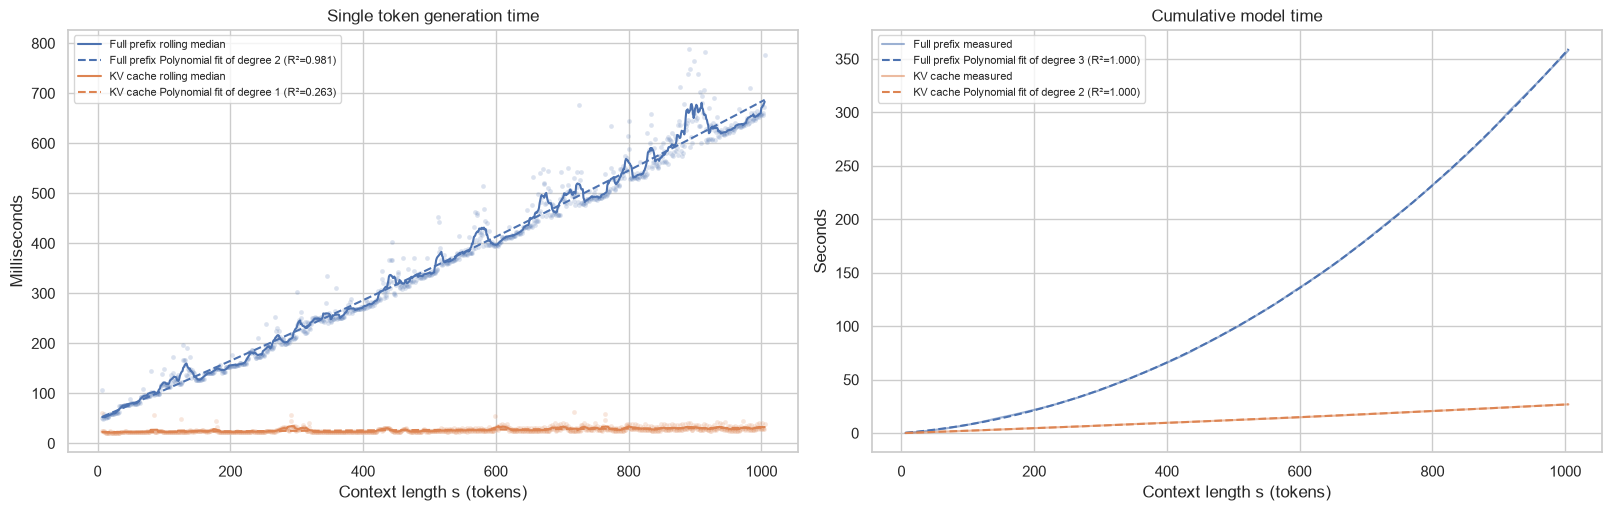

After 1000 tokens: 358.24s without cache, 26.93s with cache (13.30× speedup)


In [85]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from sklearn.metrics import r2_score


def fit_powers(x: np.ndarray, y: np.ndarray, power: int) -> tuple[np.ndarray, float]:
    fit = np.polynomial.Polynomial.fit(x, y, power)
    fitted = fit(x)
    return fitted, r2_score(y, fitted)

def rolling_median(values: np.ndarray, window: int=11):
    window_sum = np.convolve(values, np.ones(window), mode='same')
    window_counts = np.convolve(np.ones_like(values), np.ones(window), mode='same')
    return window_sum / window_counts

prompt_length = encoded["input_ids"].shape[1]
context_lengths = prompt_length + np.arange(n_tokens)  # s = P + i - 1
series = [
    ("Full prefix", np.asarray(brute_steps), 2, 3),
    ("KV cache", np.asarray(cache_steps), 1, 2),
]

sns.set_theme(style="whitegrid")
colors = sns.color_palette("deep", n_colors=2)
fig, axes = plt.subplots(1, 2, figsize=(16, 5), constrained_layout=True)

for (label, steps, step_power, total_power), color in zip(series, colors):
    step_ms = steps * 1000
    decode_ms = step_ms[1:]  # leave the prefill point out of the rolling median
    smooth_ms = rolling_median(decode_ms)
    cumulative_s = np.cumsum(steps)
    step_fit, smooth_r2 = fit_powers(context_lengths[1:], step_ms[1:], step_power)
    total_fit, total_r2 = fit_powers(context_lengths, cumulative_s, total_power)

    sns.scatterplot(x=context_lengths, y=step_ms, ax=axes[0], color=color, alpha=0.2, s=12, legend=False)

    sns.lineplot(x=context_lengths[1:], y=smooth_ms, ax=axes[0], color=color, label=f"{label} rolling median")
    sns.lineplot(x=context_lengths[1:], y=step_fit, ax=axes[0], color=color, linestyle="--", label=f"{label} Polynomial fit of degree {step_power} (R²={smooth_r2:.3f})")

    sns.lineplot(x=context_lengths, y=cumulative_s, ax=axes[1], color=color, alpha=0.55, label=f"{label} measured")
    sns.lineplot(x=context_lengths, y=total_fit, ax=axes[1], color=color, linestyle="--", label=f"{label} Polynomial fit of degree {total_power} (R²={total_r2:.3f})")

axes[0].set(title="Single token generation time", xlabel="Context length s (tokens)", ylabel="Milliseconds")
axes[1].set(title="Cumulative model time", xlabel="Context length s (tokens)", ylabel="Seconds")
for ax in axes:
    ax.legend(fontsize=8)
plt.show()

brute_total = series[0][1].sum()
cache_total = series[1][1].sum()
print(f"After {n_tokens} tokens: {brute_total:.2f}s without cache, "
      f"{cache_total:.2f}s with cache ({brute_total / cache_total:.2f}× speedup)")

### Cache use

- **Dynamic cache**
    - adds the keys and values of each new token
    - uses memory as the sequence grows
    - usual choice when output length is unknown
- **Static cache**
    - reserve space for a set number of tokens
    - the fixed size can help `torch.compile` speed up repeated calls
- **Quantized cache**
    - store keys and values with fewer bits
    - cuts memory use
    - adds work to convert values and can slow short sequences
    - lower precision can change the output
- **Cache offloading**
    - keep most cached keys and values in CPU memory
    - move next layer's cache to the GPU asynchronically
    - saves GPU memory
    - data transfer can slow decoding
- **Prefix caching**
    - save the cache for a shared prompt prefix
    - reuse it for later requests with the same token prefix
    - helps when many requests start with the same instructions or document

Sources
- [Hugging Face cache explanation](https://huggingface.co/docs/transformers/cache_explanation)
- [Hugging Face cache strategies](https://huggingface.co/docs/transformers/kv_cache)
- [vLLM prefix caching](https://docs.vllm.ai/en/latest/design/prefix_caching/)